# 02 — Baseline rule results

How do the three scenarios perform at their current (baseline) thresholds: how many alerts, how many of them are real, which laundering types are caught, and where do false alerts come from?

Rule logic: `sql/03_rules.sql`. Evaluation: `sql/04_evaluate.sql`. Definitions and assumptions: `docs/01_requirements_note.md`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "db.py").exists())
sys.path.insert(0, str(ROOT))

from src import rules
from src.db import connect

pd.set_option("display.max_rows", 60)
con = connect()
rules.prepare(con)
rules.run_rules(con, rules.BASELINE)
pd.Series(rules.BASELINE, name="baseline threshold").to_frame()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,baseline threshold
r1_band_low,1.000000e+03
r1_band_high,1.000000e+04
r1_lookback_days,9.100000e+01
r1_min_senders,1.000000e+01
r1_min_cash_deposits,8.000000e+00
r2_min_inflow,5.000000e+03
r2_min_outflow_share,7.000000e-01
r2_max_outflow_share,1.000000e+09
r2_require_risk_leg,0.000000e+00
r3_min_amount,1.000000e+04


## 1. Summary per rule
Alerts per month are averaged over the full months November 2022 – July 2023 (finding F-001). Workload assumes 20 minutes per alert and 120 review hours per FTE per month.

In [2]:
baseline = rules.summary(con)
baseline.round(2)

,alerts_total,alerts_per_month,alerted_accounts,detected_accounts,detection_pct,review_hours_per_month,fte,precision_pct
R1,52319,5290.11,8364,310,3.92,1763.37,14.69,1.95
R2,141981,13835.00,33083,1393,17.63,4611.67,38.43,1.30
R3,112757,10784.44,45311,679,8.59,3594.81,29.96,0.77
all rules,307057,29909.56,64375,1916,24.25,9969.85,83.08,1.21


## 2. Detection by laundering type
Share of laundering accounts of each type that receive at least one true alert. An account can belong to more than one type.

In [3]:
by_typology = rules.detection_by_typology(con)
by_typology.round(1)

,accounts,r1_pct,r2_pct,r3_pct,any_rule_pct
typology,,,,,
Structuring,1945,3.4,5.1,3.7,10.2
Fan_In,404,1.2,5.4,4.5,10.6
Behavioural_Change_1,447,0.0,11.4,11.6,11.9
Over-Invoicing,81,2.5,3.7,7.4,12.3
Cash_Withdrawal,176,3.4,6.8,4.0,14.2
Behavioural_Change_2,404,0.0,14.4,14.1,14.6
Single_large,295,3.4,8.1,9.8,18.0
Gather-Scatter,392,3.1,14.8,5.1,20.2
Deposit-Send,1035,4.1,20.5,6.9,22.6


In [4]:
# Structuring: the 75 collecting accounts vs the ~1,870 one-off senders.
con.sql("""
    WITH roles AS (
        SELECT DISTINCT receiver AS account, 'collecting account' AS role FROM tx WHERE typology = 'Structuring'
        UNION
        SELECT DISTINCT sender, 'one-off sender' FROM tx WHERE typology = 'Structuring'
    )
    SELECT
        r.role,
        COUNT(DISTINCT r.account) AS accounts,
        100 * COUNT(DISTINCT CASE WHEN d.rule = 'R1' THEN r.account END) / COUNT(DISTINCT r.account) AS r1_pct,
        100 * COUNT(DISTINCT d.account) / COUNT(DISTINCT r.account) AS any_rule_pct
    FROM roles r
    LEFT JOIN detections d USING (account)
    GROUP BY r.role
""").df().round(1)

,role,accounts,r1_pct,any_rule_pct
0,one-off sender,1870,0.0,6.8
1,collecting account,75,89.3,94.7


## 3. Overlap: which rules catch the same laundering accounts?

In [5]:
rules.overlap(con)

,combination,laundering_accounts
0,R2,952
1,R2 + R3,338
2,R3,316
3,R1,195
4,R1 + R2,90
5,R1 + R2 + R3,13
6,R1 + R3,12


## 4. Where do false alerts come from?
For each false alert, the normal behaviour the alerted account mostly shows (top 4 per rule).

In [6]:
false_alerts = rules.false_alerts_by_behaviour(con)
false_alerts

,rule,main_behaviour,false_alerts
0,R1,Normal_Small_Fan_Out,20672
1,R1,Normal_Group,13009
2,R1,Normal_Fan_In,10068
3,R1,Normal_Fan_Out,7546
4,R2,Normal_Small_Fan_Out,61847
5,R2,Normal_Group,37263
6,R2,Normal_Fan_Out,16330
7,R2,Normal_Fan_In,10992
8,R3,Normal_Small_Fan_Out,44988
9,R3,Normal_Fan_In,31860


## 5. Stability over time

alerts               precision_pct            
rule           R1     R2     R3            R1    R2    R3
month                                                    
2022-11-01   2385  10101   9379          1.84  1.12  0.46
2022-12-01   3882  10492   9551          2.09  1.53  0.96
2023-01-01   6131  14362  12131          2.28  1.37  0.73
2023-02-01   5304  13124  10168          1.87  1.61  0.81
2023-03-01   5258  12657   9925          1.90  1.15  0.73
2023-04-01   5547  13761  10365          2.07  1.12  0.90
2023-05-01   6768  17401  12658          1.76  1.21  0.75
2023-06-01   5513  14585  10284          1.87  1.19  0.84
2023-07-01   6823  18032  12599          1.95  1.24  0.86

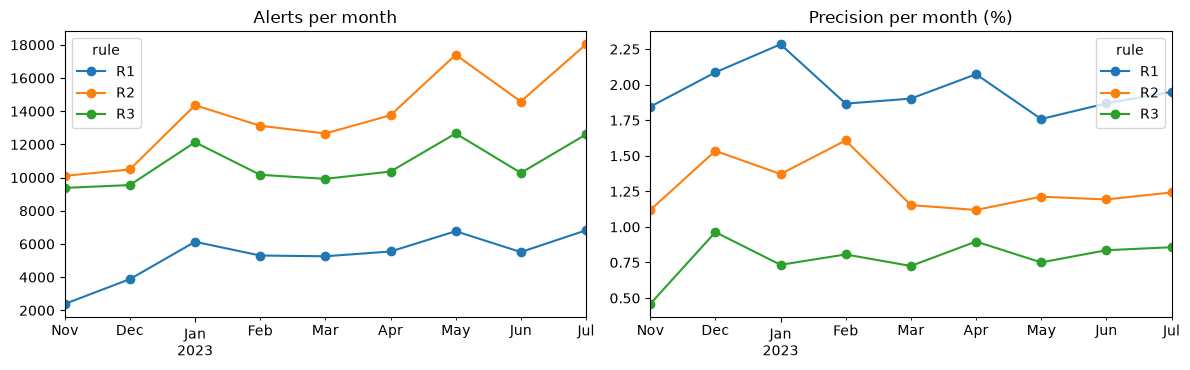

In [7]:
monthly = rules.monthly(con)
full = monthly[(monthly["month"] >= rules.FULL_MONTHS[0]) & (monthly["month"] <= rules.FULL_MONTHS[1])]
pivot_alerts = full.pivot(index="month", columns="rule", values="alerts")
pivot_precision = full.pivot(index="month", columns="rule", values="precision_pct")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
pivot_alerts.plot(ax=axes[0], marker="o", title="Alerts per month")
pivot_precision.plot(ax=axes[1], marker="o", title="Precision per month (%)")
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(ROOT / "docs" / "figures" / "02_baseline_monthly.png", dpi=150)
pd.concat({"alerts": pivot_alerts, "precision_pct": pivot_precision.round(2)}, axis=1)

## 6. Hand check: does the logic do what the requirement says?
One true and one false R2 alert, with the account's transactions in the alert week.

In [8]:
def show_alert(is_true: bool) -> pd.DataFrame:
    account, wk = con.sql(f"""
        SELECT account, wk FROM alerts_eval
        WHERE rule = 'R2' AND is_true = {is_true}
        ORDER BY hash(account, wk) LIMIT 1
    """).fetchall()[0]
    tx = con.sql(f"""
        SELECT ts, CASE WHEN receiver = {account} THEN 'in' ELSE 'out' END AS direction,
               amount, payment_type, sender_location, receiver_location, is_laundering, typology
        FROM tx
        WHERE (sender = {account} OR receiver = {account})
          AND tx_date >= DATE '{wk}' AND tx_date < DATE '{wk}' + 7
        ORDER BY ts
    """).df()
    totals = tx.groupby("direction")["amount"].sum()
    print(f"{'TRUE' if is_true else 'FALSE'} alert: account {account}, week of {wk}; "
          f"in {totals.get('in', 0):,.0f}, out {totals.get('out', 0):,.0f}")
    return tx

show_alert(True)

TRUE alert: account 6254208504, week of 2023-01-16; in 27,418, out 25,427


,ts,direction,amount,payment_type,sender_location,receiver_location,is_laundering,typology
0,2023-01-21 20:33:45,in,27417.537736,ACH,UK,UK,1,Cycle
1,2023-01-22 06:48:27,out,25426.926923,Credit card,UK,UK,1,Cycle


In [9]:
show_alert(False)

FALSE alert: account 4998213450, week of 2023-01-30; in 5,320, out 18,635


,ts,direction,amount,payment_type,sender_location,receiver_location,is_laundering,typology
0,2023-01-31 12:35:00,in,5320.50,Cash Deposit,UK,UK,0,Normal_Cash_Deposits
1,2023-02-03 14:25:07,out,18635.03,Cheque,UK,UK,0,Normal_Foward


In [10]:
(ROOT / "docs" / "results").mkdir(exist_ok=True)
baseline.to_csv(ROOT / "docs" / "results" / "baseline_summary.csv")
by_typology.to_csv(ROOT / "docs" / "results" / "baseline_detection_by_typology.csv")

## 7. Findings

1. **The request is confirmed by the numbers.** At baseline the three rules produce about 29,900 alerts per month (≈ 83 FTE at 20 minutes per alert) and catch 2,169 of 7,902 laundering accounts (27%). R2 alone produces 13,800 alerts per month (38 FTE) with a precision of 1.3%: about 1 real case in 77 alerts.
2. **R2 is still the most valuable rule for detection.** It catches 1,393 laundering accounts, 842 of them caught by no other rule. Simply switching it off would cut detection from 27% to about 17%.
3. **Hand check found a specification gap in R2.** The requirement is "most incoming money leaves the account again in the same week", but the rule only checks that outflow is at least 70% of inflow, with no upper limit. A sampled false alert received £5,320 and paid out £18,635: an account spending its balance, not passing money through. Adding an upper bound is a candidate change for Day 3 (finding F-007).
4. **"Detection" depends on which accounts count.** For structuring, R1 catches 89% of the 75 collecting accounts but only 4% of the 1,870 one-off senders, so the per-account figure (16%) understates how well the scheme itself is found. This needs a decision from compliance (finding F-008).
5. **Coverage is uneven by laundering type.** Cycle (80%) and smurfing (64%) are caught well; behavioural change, fan-in, structuring senders and over-invoicing stay below 20% with any rule. These gaps exist before any threshold change and should be reported separately.
6. **False alerts come from the large normal look-alike behaviours**, mainly Normal_Small_Fan_Out, Normal_Group, Normal_Fan_In and Normal_Fan_Out. Changes that separate these from laundering will cut most alerts.
7. **Alert volumes rise over the period while transaction volume is flat.** R1 starts low partly because its 91-day lookback has little history in the first months (warm-up); R2 and R3 also rise (by 78% and 34% from November to July). Precision is stable (R1 4–6%, R2 1.1–1.6%, R3 0.7–1.2%). Month-to-month comparisons of options should use the same months (finding F-009).